<a href="https://colab.research.google.com/github/Apurba213/Ostad_AI-Ml-engineering-course/blob/main/Model10_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

              DIABETES DETECTION SYSTEM

Dataset loaded successfully!

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

DATASET INFORMATION

Dataset Shape:
(768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data Types:
Pregnancies        

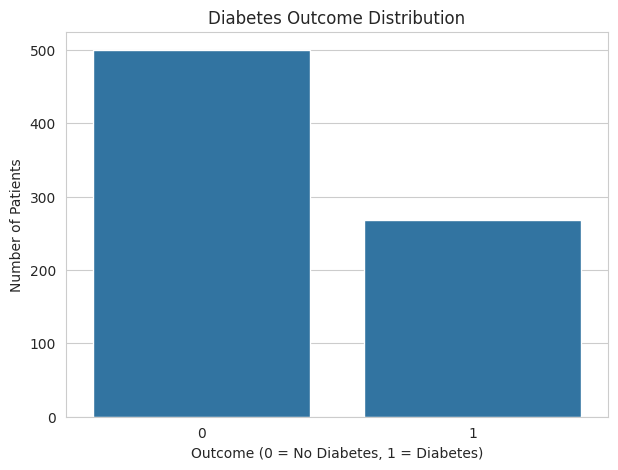

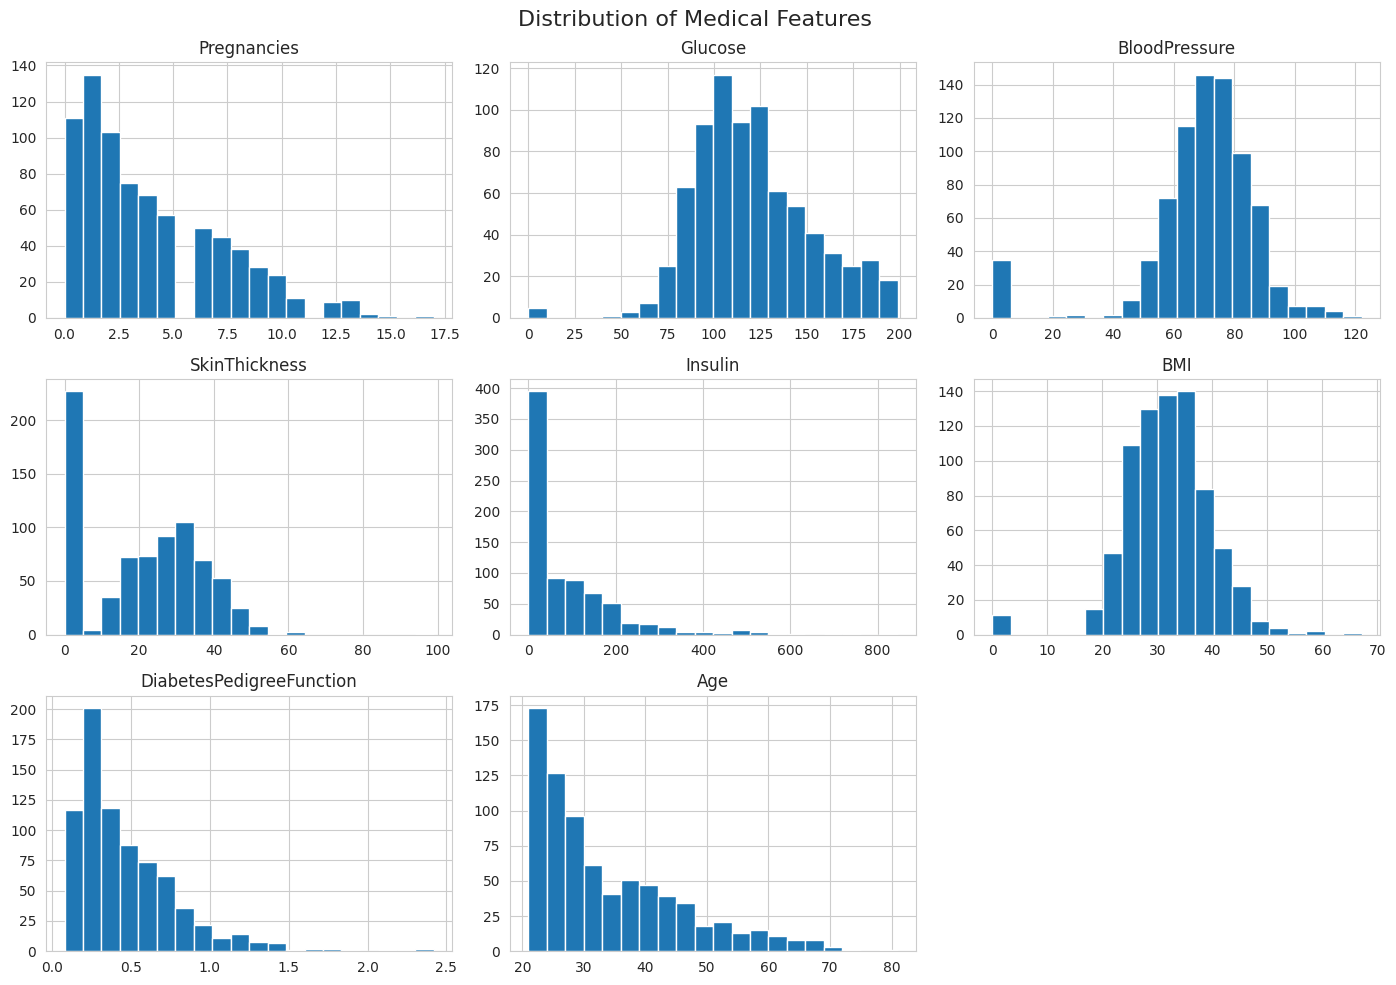

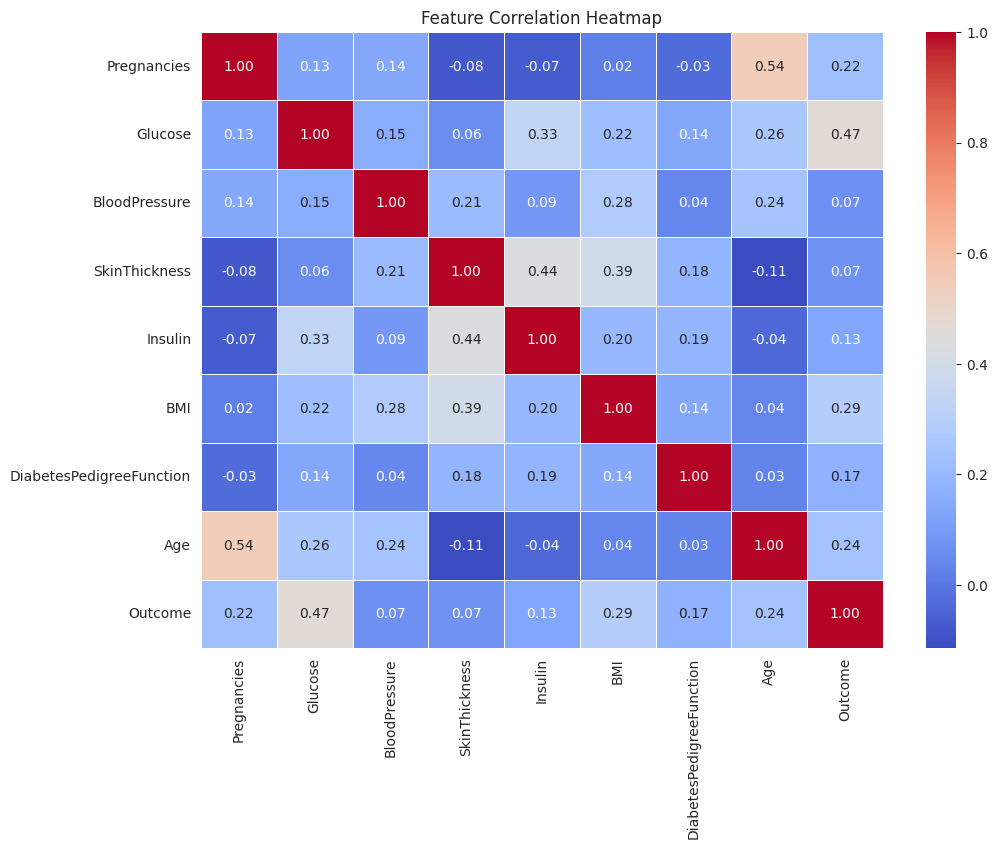

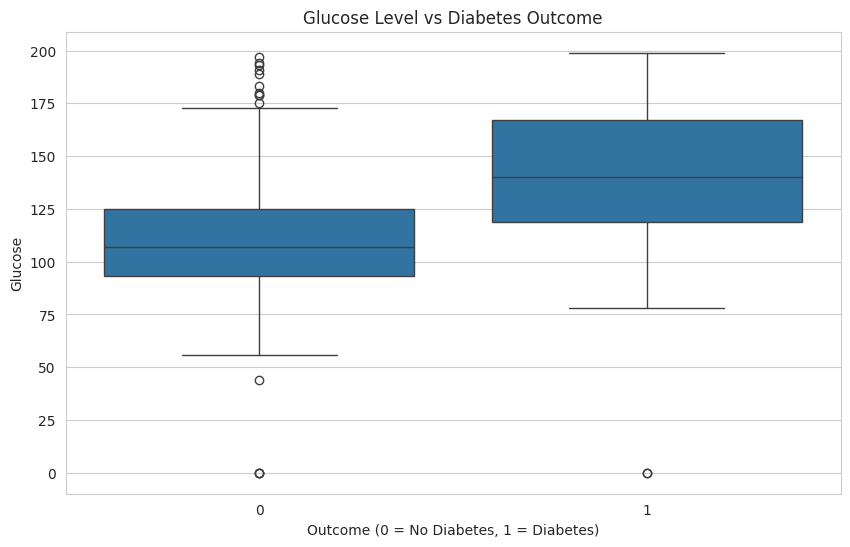


FEATURES AND TARGET

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
Outcome

TRAIN-TEST SPLIT
Training samples: 614
Testing samples : 154

Feature scaling completed.

ALL MODELS TRAINED SUCCESSFULLY

Logistic Regression
Accuracy : 0.7143
Precision: 0.6087
Recall   : 0.5185
F1-Score : 0.5600
ROC-AUC  : 0.8230

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.82      0.79       100
           1       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154


K-Nearest Neighbors
Accuracy : 0.7013
Precision: 0.5833
Recall   : 0.5185
F1-Score : 0.5490
ROC-AUC  : 0.7405

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
        

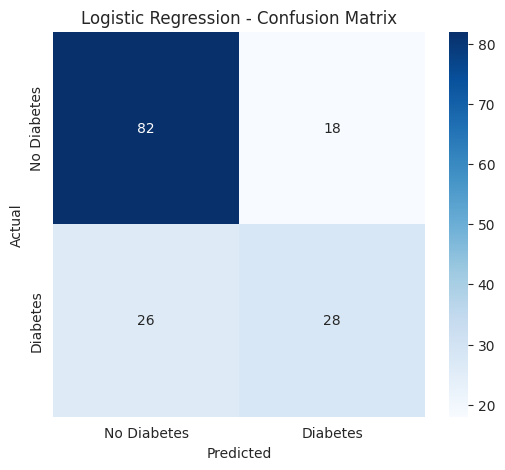

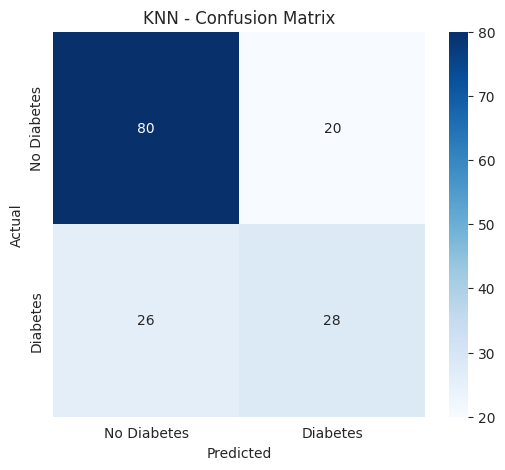

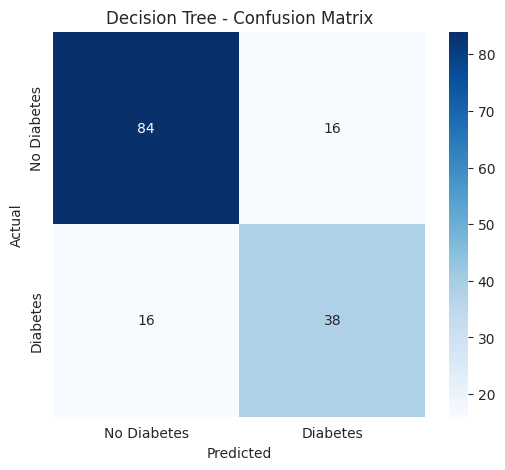

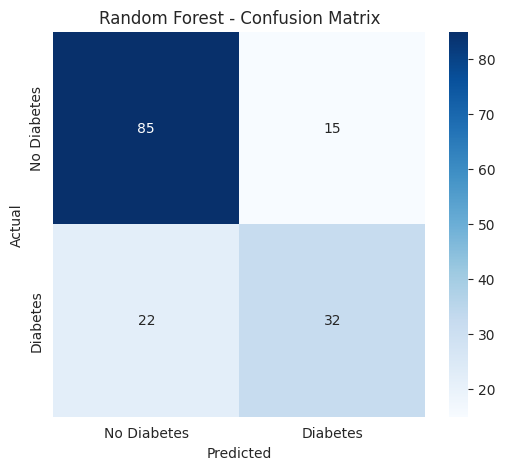

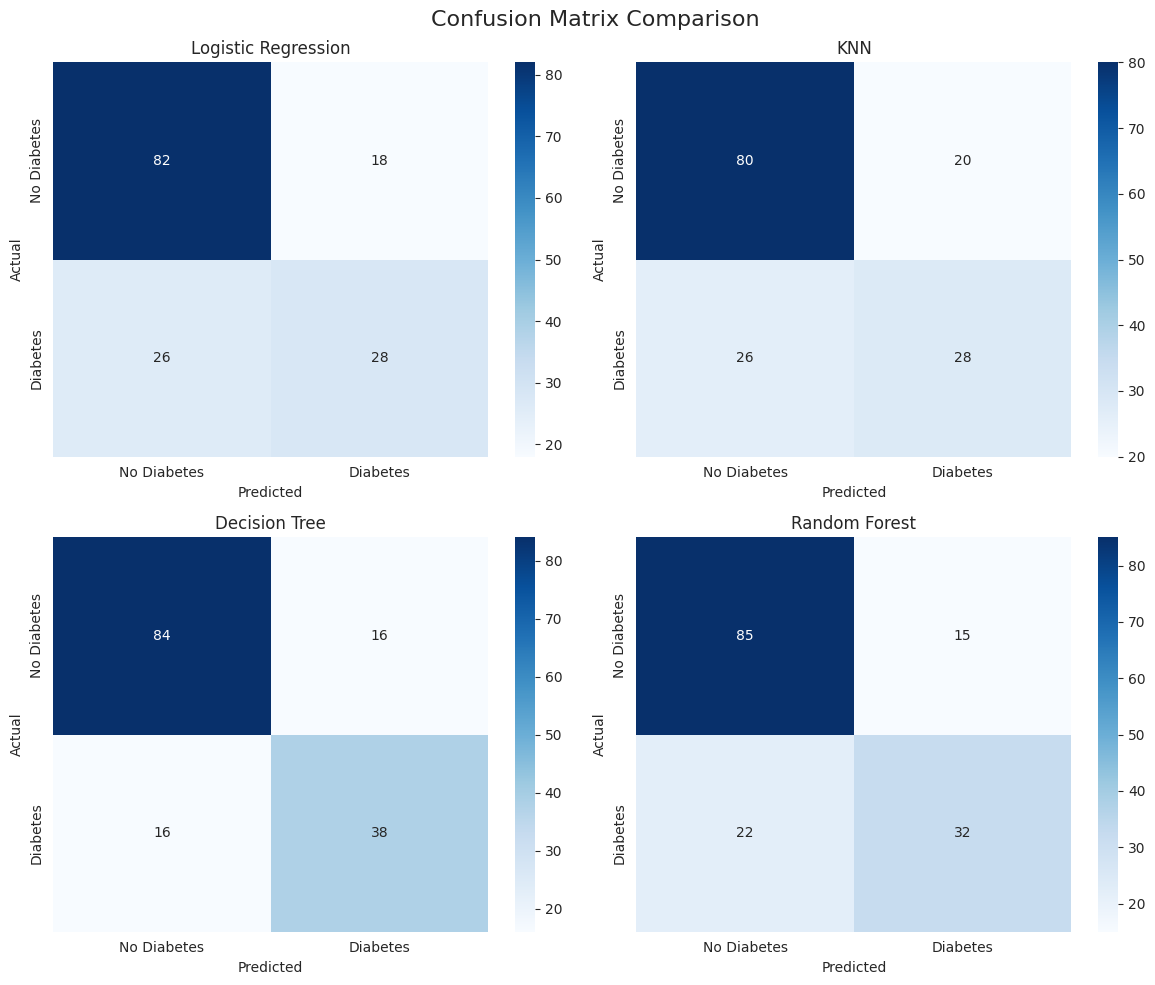

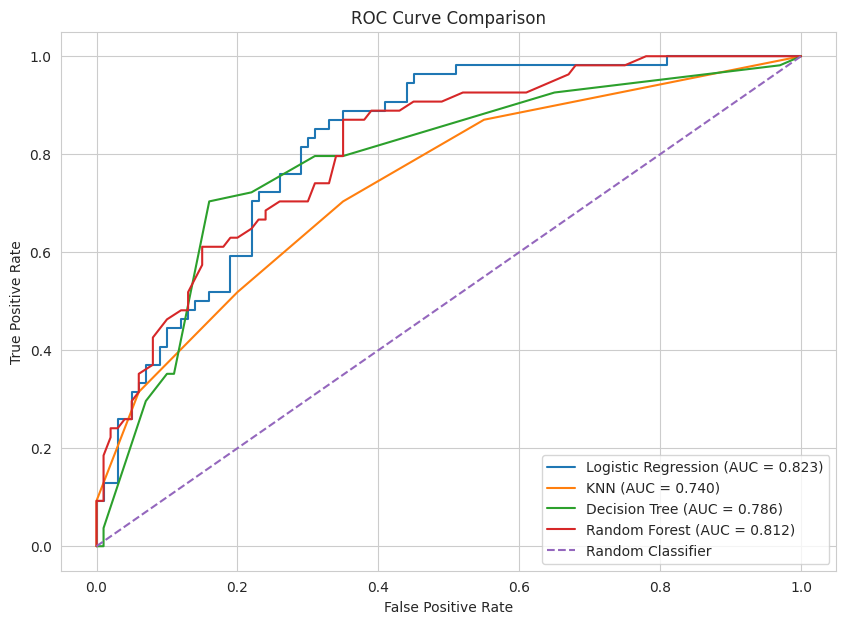

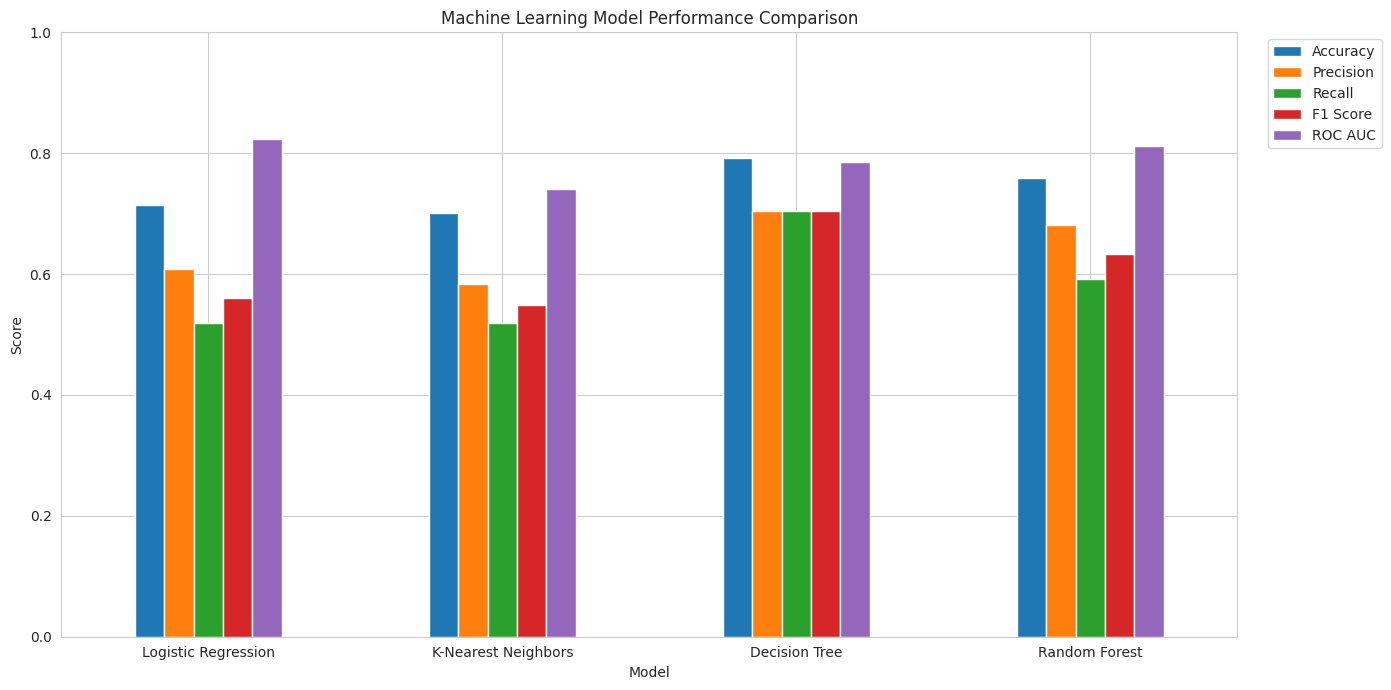

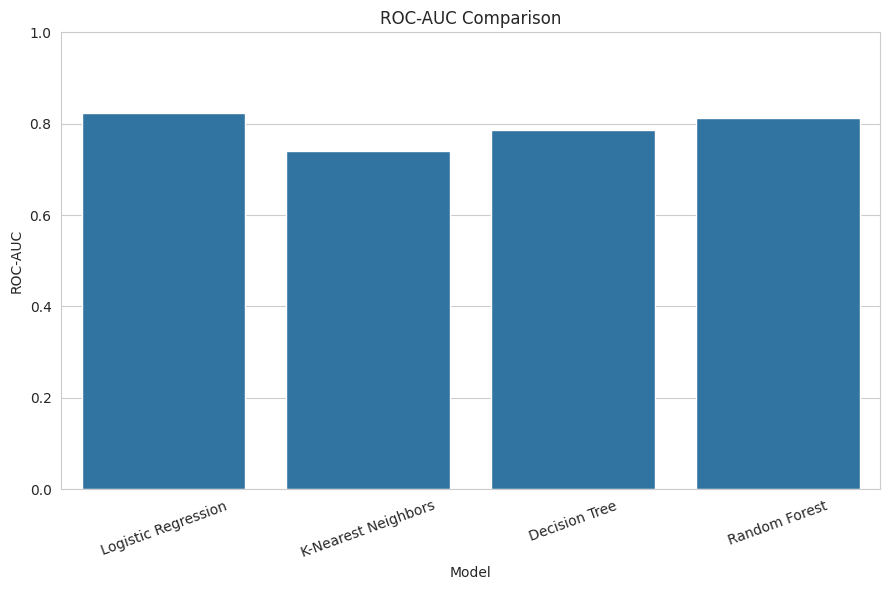


RANDOM FOREST FEATURE IMPORTANCE
                 Feature  Importance
                 Glucose    0.276009
                     BMI    0.159544
                     Age    0.127248
DiabetesPedigreeFunction    0.126731
           BloodPressure    0.085606
             Pregnancies    0.084456
                 Insulin    0.072409
           SkinThickness    0.067997


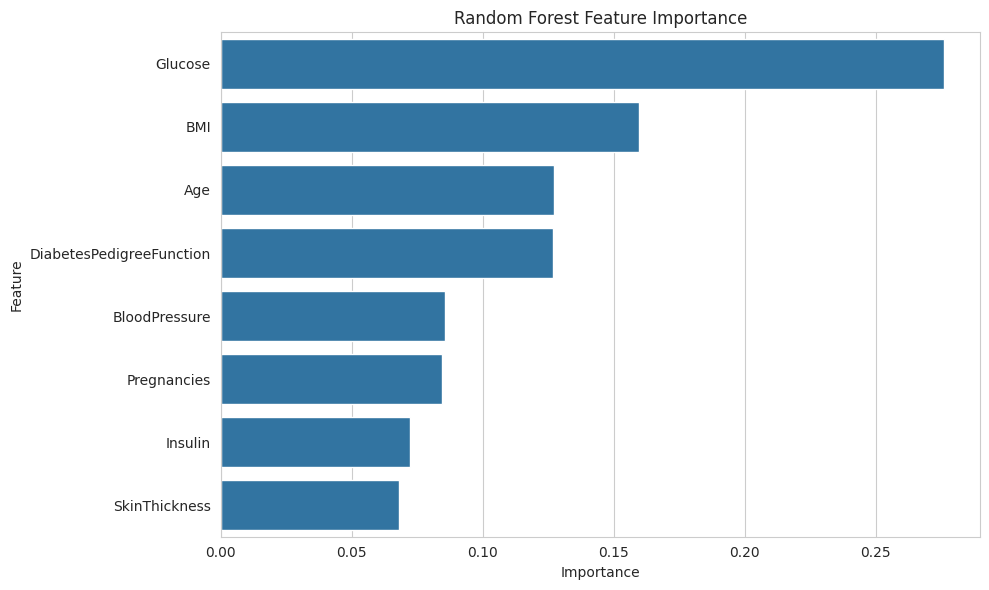


LOGISTIC REGRESSION COEFFICIENTS
                 Feature  Coefficient  Absolute Coefficient
                 Glucose     1.144151              1.144151
                     BMI     0.713893              0.713893
             Pregnancies     0.373178              0.373178
DiabetesPedigreeFunction     0.255527              0.255527
           BloodPressure    -0.197637              0.197637
                     Age     0.184179              0.184179
                 Insulin    -0.127308              0.127308
           SkinThickness     0.066535              0.066535

FINAL MODEL
Selected model based on highest ROC-AUC: Logistic Regression

NEW PATIENT PREDICTION
Prediction: NO DIABETES
Diabetes Probability: 24.40%

Random Forest Prediction:
Prediction: NO DIABETES
Diabetes Probability: 36.00%

FINAL PROJECT SUMMARY

Dataset:
Diabetes Dataset

Number of Features:
8

Training Samples:
614

Testing Samples:
154

Models Used:
1. Logistic Regression
2. K-Nearest Neighbors
3. Decision Tree


In [1]:
# PROJECT: DIABETES DETECTION SYSTEM
# Algorithms:
# 1. Logistic Regression
# 2. K-Nearest Neighbors (KNN)
# 3. Decision Tree
# 4. Random Forest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

# Plot style
sns.set_style("whitegrid")

print("=" * 70)
print("              DIABETES DETECTION SYSTEM")
print("=" * 70)

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)

print("\nDataset loaded successfully!")

print("\nFirst 5 rows:")
print(df.head())

print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()




print("\n" + "=" * 70)
print("STATISTICAL SUMMARY")
print("=" * 70)

print(df.describe())

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing_values = df.isnull().sum()

print(missing_values)

if missing_values.sum() == 0:
    print("\nNo missing values found.")
else:
    print("\nMissing values found.")

print("\n" + "=" * 70)
print("DUPLICATE VALUES")
print("=" * 70)

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")


print("\n" + "=" * 70)
print("TARGET VARIABLE DISTRIBUTION")
print("=" * 70)

print(df["Outcome"].value_counts())

print("\nPercentage distribution:")
print(df["Outcome"].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(
    x="Outcome",
    data=df
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")

plt.show()



features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

df[features].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Medical Features", fontsize=16)

plt.tight_layout()

plt.show()



plt.figure(figsize=(11, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.show()

plt.figure(figsize=(10, 6))

sns.boxplot(
    x="Outcome",
    y="Glucose",
    data=df
)

plt.title("Glucose Level vs Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Glucose")

plt.show()
X = df.drop("Outcome", axis=1)

y = df["Outcome"]

print("\n" + "=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print("Outcome")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 70)
print("TRAIN-TEST SPLIT")
print("=" * 70)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed.")

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_pred = logistic_model.predict(
    X_test_scaled
)

logistic_prob = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_pred = knn_model.predict(
    X_test_scaled
)

knn_prob = knn_model.predict_proba(
    X_test_scaled
)[:, 1]

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_pred = decision_tree_model.predict(
    X_test
)

decision_tree_prob = decision_tree_model.predict_proba(
    X_test
)[:, 1]

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_pred = random_forest_model.predict(
    X_test
)

random_forest_prob = random_forest_model.predict_proba(
    X_test
)[:, 1]


print("\n" + "=" * 70)
print("ALL MODELS TRAINED SUCCESSFULLY")
print("=" * 70)

def evaluate_model(model_name, y_true, y_pred, y_prob):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc
    }

logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred,
    logistic_prob
)
knn_results = evaluate_model(
    "K-Nearest Neighbors",
    y_test,
    knn_pred,
    knn_prob
)

decision_tree_results = evaluate_model(
    "Decision Tree",
    y_test,
    decision_tree_pred,
    decision_tree_prob
)

random_forest_results = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_pred,
    random_forest_prob
)
results = [
    logistic_results,
    knn_results,
    decision_tree_results,
    random_forest_results
]

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

print(
    results_df.round(4).to_string(index=False)
)
best_auc_index = results_df["ROC AUC"].idxmax()

best_model_auc = results_df.loc[best_auc_index]

print("\n" + "=" * 70)
print("BEST MODEL BASED ON ROC-AUC")
print("=" * 70)

print("Model:", best_model_auc["Model"])
print("ROC-AUC:", round(best_model_auc["ROC AUC"], 4))


best_f1_index = results_df["F1 Score"].idxmax()

best_model_f1 = results_df.loc[best_f1_index]

print("\nBest Model based on F1 Score:")
print("Model:", best_model_f1["Model"])
print("F1 Score:", round(best_model_f1["F1 Score"], 4))

cm_logistic = confusion_matrix(
    y_test,
    logistic_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Logistic Regression - Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

cm_knn = confusion_matrix(
    y_test,
    knn_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("KNN - Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

cm_decision_tree = confusion_matrix(
    y_test,
    decision_tree_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_decision_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Decision Tree - Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

cm_random_forest = confusion_matrix(
    y_test,
    random_forest_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_random_forest,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Random Forest - Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

confusion_matrices = [
    ("Logistic Regression", logistic_pred),
    ("KNN", knn_pred),
    ("Decision Tree", decision_tree_pred),
    ("Random Forest", random_forest_pred)
]

for ax, (name, predictions) in zip(
    axes.ravel(),
    confusion_matrices
):

    cm = confusion_matrix(
        y_test,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"],
        ax=ax
    )

    ax.set_title(name)

    ax.set_xlabel("Predicted")

    ax.set_ylabel("Actual")


plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=16
)

plt.tight_layout()

plt.show()

fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    logistic_prob
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test,
    knn_prob
)

fpr_decision_tree, tpr_decision_tree, _ = roc_curve(
    y_test,
    decision_tree_prob
)

fpr_random_forest, tpr_random_forest, _ = roc_curve(
    y_test,
    random_forest_prob
)
auc_logistic = roc_auc_score(
    y_test,
    logistic_prob
)

auc_knn = roc_auc_score(
    y_test,
    knn_prob
)

auc_decision_tree = roc_auc_score(
    y_test,
    decision_tree_prob
)

auc_random_forest = roc_auc_score(
    y_test,
    random_forest_prob
)


plt.figure(figsize=(10, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {auc_logistic:.3f})"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN (AUC = {auc_knn:.3f})"
)

plt.plot(
    fpr_decision_tree,
    tpr_decision_tree,
    label=f"Decision Tree (AUC = {auc_decision_tree:.3f})"
)

plt.plot(
    fpr_random_forest,
    tpr_random_forest,
    label=f"Random Forest (AUC = {auc_random_forest:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.grid(True)

plt.show()

performance_plot = results_df.set_index("Model")

performance_plot[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ]
].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Machine Learning Model Performance Comparison")

plt.xlabel("Model")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

plt.figure(figsize=(9, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC AUC"
)

plt.title("ROC-AUC Comparison")

plt.xlabel("Model")

plt.ylabel("ROC-AUC")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n" + "=" * 70)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 70)

print(
    feature_importance.to_string(index=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.tight_layout()

plt.show()


logistic_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

logistic_coefficients["Absolute Coefficient"] = (
    logistic_coefficients["Coefficient"].abs()
)

logistic_coefficients = logistic_coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("\n" + "=" * 70)
print("LOGISTIC REGRESSION COEFFICIENTS")
print("=" * 70)

print(
    logistic_coefficients.to_string(index=False)
)

model_objects = {
    "Logistic Regression": logistic_model,
    "K-Nearest Neighbors": knn_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("\n" + "=" * 70)
print("FINAL MODEL")
print("=" * 70)

best_model_name = best_model_auc["Model"]

print(
    "Selected model based on highest ROC-AUC:",
    best_model_name
)
new_patient = pd.DataFrame(
    [[
        2,       # Pregnancies
        120,     # Glucose
        70,      # BloodPressure
        30,      # SkinThickness
        100,     # Insulin
        32.5,    # BMI
        0.35,    # DiabetesPedigreeFunction
        35       # Age
    ]],
    columns=X.columns
)

new_patient_scaled = scaler.transform(
    new_patient
)

patient_prediction = logistic_model.predict(
    new_patient_scaled
)

patient_probability = logistic_model.predict_proba(
    new_patient_scaled
)[0][1]


print("\n" + "=" * 70)
print("NEW PATIENT PREDICTION")
print("=" * 70)

if patient_prediction[0] == 1:

    print("Prediction: DIABETES")

else:

    print("Prediction: NO DIABETES")

print(
    f"Diabetes Probability: {patient_probability:.2%}"
)

rf_patient_prediction = random_forest_model.predict(
    new_patient
)

rf_patient_probability = random_forest_model.predict_proba(
    new_patient
)[0][1]


print("\nRandom Forest Prediction:")

if rf_patient_prediction[0] == 1:

    print("Prediction: DIABETES")

else:

    print("Prediction: NO DIABETES")

print(
    f"Diabetes Probability: {rf_patient_probability:.2%}"
)

print("\n" + "=" * 70)
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print("\nDataset:")
print("Diabetes Dataset")

print("\nNumber of Features:")
print(X.shape[1])

print("\nTraining Samples:")
print(X_train.shape[0])

print("\nTesting Samples:")
print(X_test.shape[0])

print("\nModels Used:")
print("1. Logistic Regression")
print("2. K-Nearest Neighbors")
print("3. Decision Tree")
print("4. Random Forest")

print("\nBest Model based on ROC-AUC:")
print(best_model_name)

print(
    f"\nBest ROC-AUC: "
    f"{best_model_auc['ROC AUC']:.4f}"
)

print("\nProject completed successfully!")
